In [3]:
import numpy as np
from astropy.table import QTable

In [2]:
# Fixed PSD NET (per det)
# NET_per_det = NET_coadded * sqrt(active N_dets)

In [8]:
# 280 GHz
NET_coadded = 13 # uK sqrt(s)
N_dets = 10368
NET_per_det = NET_coadded * np.sqrt(0.8 * N_dets)
np.round(NET_per_det,2)

np.float64(1183.96)

In [9]:
1183.96e-6

0.00118396

In [10]:
hf_fulltable_file = "fp_f280_dettable.h5"
dettable_stack = QTable.read(hf_fulltable_file, path='dettable_stack')

In [11]:
dettable_stack[:10]

name,quat,wafer_slot,band,pixel,pol,psi_pol,gamma,fwhm,psd_fmin,psd_fknee,psd_alpha,psd_net,bandcenter,bandwidth,index
,,,,,,rad,rad,arcmin,Hz,Hz,,K s(1/2),GHz,GHz,
bytes18,float64[4],bytes2,bytes7,bytes4,bytes1,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64
w1_p0000_PC_f280_A,-0.005072369529069076 .. 0.8660163784700161,w1,PC_f280,0000,A,0.0,-4.188797643359865,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,0
w1_p0000_PC_f280_B,-0.00359336894481511 .. 0.9659123048403945,w1,PC_f280,0000,B,1.5707963267948966,-2.618001316564968,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,1
w1_p0001_PC_f280_A,-0.004572088942740462 .. 0.9914331492268191,w1,PC_f280,0001,A,0.0,-3.403399156542151,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,2
w1_p0001_PC_f280_B,-0.0018555723922789613 .. 0.7933410642370625,w1,PC_f280,0001,B,1.5707963267948966,-1.8326028297472545,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,3
w1_p0002_PC_f280_A,-0.0046175479542572805 .. 0.9914331900795174,w1,PC_f280,0002,A,0.0,-3.4033991565434794,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,4
w1_p0002_PC_f280_B,-0.0019653210881174056 .. 0.7933408676473932,w1,PC_f280,0002,B,1.5707963267948966,-1.8326028297485832,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,5
w1_p0003_PC_f280_A,-0.0048666175967926675 .. 0.8660170990677891,w1,PC_f280,0003,A,0.0,-4.188796996519891,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,6
w1_p0003_PC_f280_B,-0.0033638815978493945 .. 0.9659133694647355,w1,PC_f280,0003,B,1.5707963267948966,-2.6180006697249945,0.78,0.001,1.0,1.0,0.00118396,280.0,60.0,7


In [12]:
trim_dettable_w2 = dettable_stack[dettable_stack['wafer_slot'] == 'w2']

In [14]:
print(trim_dettable_w2["index"])

index
-----
 3426
 3427
 3428
 3429
 3430
 3431
 3432
 3433
 3434
 3435
  ...
 6842
 6843
 6844
 6845
 6846
 6847
 6848
 6849
 6850
 6851
Length = 3426 rows


In [15]:
from visualize_fp import plot_focalplane_primecam
from astropy.table import QTable
from toast.instrument import Focalplane
import matplotlib.pyplot as plt
import astropy.units as u

In [16]:
width= 1.2 * u.degree
fp_w2 =  Focalplane(
                detector_data=trim_dettable_w2)

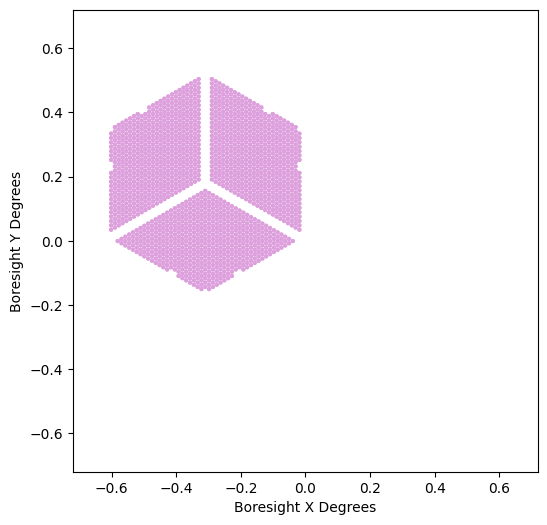

In [17]:
plot_focalplane_primecam(
    focalplane=fp_w2,
    width=width,
    height=width,
    show_labels=False,
    # outfile="fp_280gz_rot3_2024.pdf"
)
plt.show()

In [13]:
len(trim_dettable_w2)

3426

In [15]:
import numpy as np

In [141]:
dets_toselect = 1000
# 1) Get the first and last entry from the 'index' column
first_index = trim_dettable_w2["index"][0]
last_index = trim_dettable_w2["index"][-1]

# 2) Select `pairs_select` number of linspace values from 'index'
pairs_select = dets_toselect // 2
linspace_indices = np.linspace(first_index, last_index, pairs_select, dtype=int)

# 3) For each of those indices, get the corresponding 'pixel' values from the table
pixels_select = trim_dettable_w2[np.isin(trim_dettable_w2["index"], linspace_indices)]['pixel']

# 4) Format the pixel values into byte strings in bytes4 format
pixel_strings = [f"{int(pixel):04}".encode('utf-8') for pixel in pixels_select]

# Output the formatted bytes4 strings
print(len(pixel_strings))

print(f"Number of selected pixels: {len(pixel_strings)}")


# # Create a boolean mask where 'True' indicates a match in 'pixel_strings'
mask = np.isin(trim_dettable_w2['pixel'], pixel_strings)

# # Apply the mask to filter the table
sel_dettable = trim_dettable_w2[mask]

print(f"Number of selected detectors: {len(sel_dettable)}")

500
Number of selected pixels: 500
Number of selected detectors: 1000


In [139]:
sel_dettable[-10:]

name,quat,wafer_slot,band,pixel,pol,psi_pol,gamma,fwhm,psd_fmin,psd_fknee,psd_alpha,psd_net,bandcenter,bandwidth,index,uid,pol_angle,pol_efficiency,pol_leakage
,,,,,,rad,rad,arcmin,Hz,Hz,,K s(1/2),GHz,GHz,,,rad,,
bytes18,float64[4],bytes2,bytes7,bytes4,bytes1,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64
w2_p1585_PC_f280_A,-0.0007791432645057415 .. 0.8660212175574543,w2,PC_f280,1585,A,0.0,2.263903137844636e-06,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6570,1446885891,1.0472073582678523,1.0,0.0
w2_p1585_PC_f280_B,-0.0018544866667595987 .. 0.2588137903009866,w2,PC_f280,1585,B,1.5707963267948966,1.5707985906980348,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6571,4088937638,2.6180036850627495,1.0,0.0
w2_p1621_PC_f280_A,-0.00026476162587702867 .. 0.8660207097964193,w2,PC_f280,1621,A,0.0,2.91073708069689e-06,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6640,3730024313,1.0472099339508703,1.0,0.0
w2_p1621_PC_f280_B,-0.0015327605802413658 .. 0.25881258703541254,w2,PC_f280,1621,B,1.5707963267948966,1.570799237531977,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6641,3365393520,2.6180062607457666,1.0,0.0
w2_p1657_PC_f280_A,-0.00105338247766288 .. 0.6087569924815517,w2,PC_f280,1657,A,0.0,0.785402044377701,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6710,2040831901,1.8326052098585772,1.0,0.0
w2_p1657_PC_f280_B,-0.001483599856254827 .. -0.13053075557795268,w2,PC_f280,1657,B,1.5707963267948966,2.3561983711725976,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6711,2099574879,0.26180888306368066,1.0,0.0
w2_p1692_PC_f280_A,-0.0010884922139321866 .. 0.6087585422171505,w2,PC_f280,1692,A,0.0,0.7854033380398171,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6780,3264139106,1.8326020028283694,1.0,0.0
w2_p1692_PC_f280_B,-0.0009980883993810986 .. -0.13052922530186917,w2,PC_f280,1692,B,1.5707963267948966,2.3561996648347145,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,6781,1900577552,0.26180567603347304,1.0,0.0


In [44]:
# List of pixel values to filter
# the pixel column in QTable is of type bytes4, it contains byte strings (b'0000')
filter_pixels = [b'0000', b'0428', b'0856', b'1284', b'1712']

# Convert the list to a numpy array for comparison
filter_array = np.array(filter_pixels)

# Create a boolean mask where 'True' indicates a match in 'filter_pixels'
mask = np.isin(trim_dettable_w2['pixel'], filter_array)

print(mask)
# Apply the mask to filter the table
filtered_table = trim_dettable_w2[mask]

[False False False ... False False False]


In [42]:
filtered_table

name,quat,wafer_slot,band,pixel,pol,psi_pol,gamma,fwhm,psd_fmin,psd_fknee,psd_alpha,psd_net,bandcenter,bandwidth,index,uid,pol_angle,pol_efficiency,pol_leakage
,,,,,,rad,rad,arcmin,Hz,Hz,,K s(1/2),GHz,GHz,,,rad,,
bytes18,float64[4],bytes2,bytes7,bytes4,bytes1,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,int64,float64,float64,float64
w2_p0000_PC_f280_A,-0.0023661384776333906 .. 0.8660078708992881,w2,PC_f280,0000,A,0.0,-4.188797643359865,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,3426,3274576627,2.0943728756412945,1.0,0.0
w2_p0000_PC_f280_B,-0.004994188749293239 .. 0.9659153448046767,w2,PC_f280,0000,B,1.5707963267948966,-2.618001316564968,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,3427,656262584,0.5235765488463981,1.0,0.0
w2_p0428_PC_f280_A,0.0007201273184359429 .. 0.866018712946903,w2,PC_f280,0428,A,0.0,2.0943973662943796,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,4276,4037732206,2.0944018670119884,1.0,0.0
w2_p0428_PC_f280_B,-0.0025598854326849786 .. 0.9659156020121606,w2,PC_f280,0428,B,1.5707963267948966,-2.61799161409031,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,4277,3183110447,0.5236055402170927,1.0,0.0
w2_p0856_PC_f280_A,0.001227213170627933 .. 0.38268017989849756,w2,PC_f280,0856,A,0.0,-1.3089969389957474,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,5124,912183689,0.7853944779332633,1.0,0.0
w2_p0856_PC_f280_B,-0.0009480866221672107 .. 0.9238750852734657,w2,PC_f280,0856,B,1.5707963267948966,-6.021385919380437,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,5125,3244842821,2.35619080472816,1.0,0.0
w2_p1284_PC_f280_A,-0.002468772633505179 .. 0.6087530314057119,w2,PC_f280,1284,A,0.0,0.7853955760773648,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,5972,3217248329,1.8326071000508763,1.0,0.0
w2_p1284_PC_f280_B,-0.0035700364179516663 .. -0.13053100401317314,w2,PC_f280,1284,B,1.5707963267948966,2.3561919028722613,0.78,0.001,1.0,1.0,1.3e-05,280.0,60.0,5973,374121412,0.26181077325597935,1.0,0.0


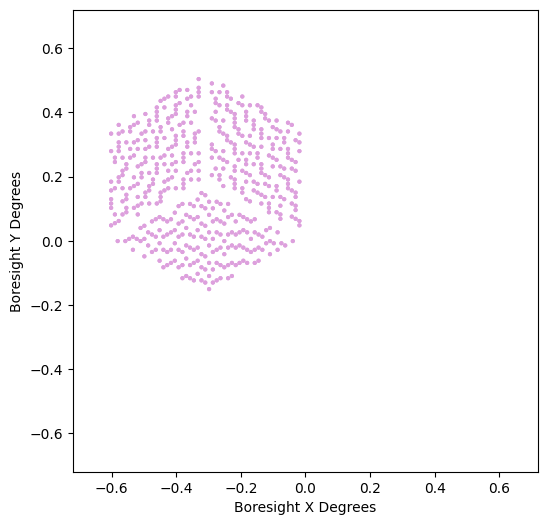

In [144]:
width= 1.2 * u.degree
trim_fp_w2 =  Focalplane(
                detector_data=sel_dettable)

plot_focalplane_primecam(
    focalplane=trim_fp_w2,
    width=width,
    height=width,
    show_labels=False,
    # outfile="fp_280gz_rot3_2024.pdf"
)
plt.show()